In [1]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timedelta
plt.style.use('fivethirtyeight')

In [2]:
end = datetime.now()
start = datetime(end.year-15, end.month, end.day)
crypto = 'ETH-USD'
crypto_data = yf.download(crypto, start=start, end = end)

[*********************100%***********************]  1 of 1 completed


In [3]:
crypto_data.head()

Price,Close,High,Low,Open,Volume
Ticker,ETH-USD,ETH-USD,ETH-USD,ETH-USD,ETH-USD
Date,,,,,
2017-11-09,320.884003,329.451996,307.056000,308.644989,893249984
2017-11-10,299.252991,324.717987,294.541992,320.670990,885985984
2017-11-11,314.681000,319.453003,298.191986,298.585999,842300992
2017-11-12,307.907990,319.153015,298.513000,314.690002,1613479936
2017-11-13,316.716003,328.415009,307.024994,307.024994,1041889984


In [4]:
crypto_data.tail()

Price,Close,High,Low,Open,Volume
Ticker,ETH-USD,ETH-USD,ETH-USD,ETH-USD,ETH-USD
Date,,,,,
2026-11-15,1835.495239,1843.145020,1712.383179,1769.120483,15785301494
2026-11-16,1819.275879,1863.969971,1785.534790,1835.495239,11738710877
2026-11-17,1822.961304,1840.695068,1750.463745,1819.275879,12860752571
2026-11-18,1774.749146,1824.274536,1732.707153,1822.961304,10746861848
2026-11-19,1795.339966,1811.701050,1764.526123,1774.707764,10517813248


In [5]:
crypto_data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3298 entries, 2017-11-09 to 2026-11-19
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   (Close, ETH-USD)   3298 non-null   float64
 1   (High, ETH-USD)    3298 non-null   float64
 2   (Low, ETH-USD)     3298 non-null   float64
 3   (Open, ETH-USD)    3298 non-null   float64
 4   (Volume, ETH-USD)  3298 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 154.6 KB


In [6]:
crypto_data.describe()

Price,Close,High,Low,Open,Volume
Ticker,ETH-USD,ETH-USD,ETH-USD,ETH-USD,ETH-USD
count,3298.000000,3298.000000,3298.000000,3298.000000,3.298000e+03
mean,1737.293051,1782.779482,1686.995215,1736.973799,1.505421e+10
std,1247.260518,1279.493537,1212.747726,1247.690955,1.200808e+10
min,84.308296,85.342743,82.829887,84.279694,6.217330e+08
25%,400.068108,413.922005,386.524139,399.462433,6.640396e+09
50%,1794.368286,1827.387695,1745.321167,1793.830566,1.246587e+10
75%,2628.703003,2695.907043,2555.358398,2628.403992,1.990675e+10
max,4831.348633,4953.732910,4718.039062,4831.088379,9.773662e+10


In [7]:
closing_price = crypto_data[['Close']]

In [8]:
closing_price['Close']

Ticker,ETH-USD
Date,
2017-11-09,320.884003
2017-11-10,299.252991
2017-11-11,314.681000
2017-11-12,307.907990
2017-11-13,316.716003
...,...
2026-11-15,1835.495239
2026-11-16,1819.275879
2026-11-17,1822.961304


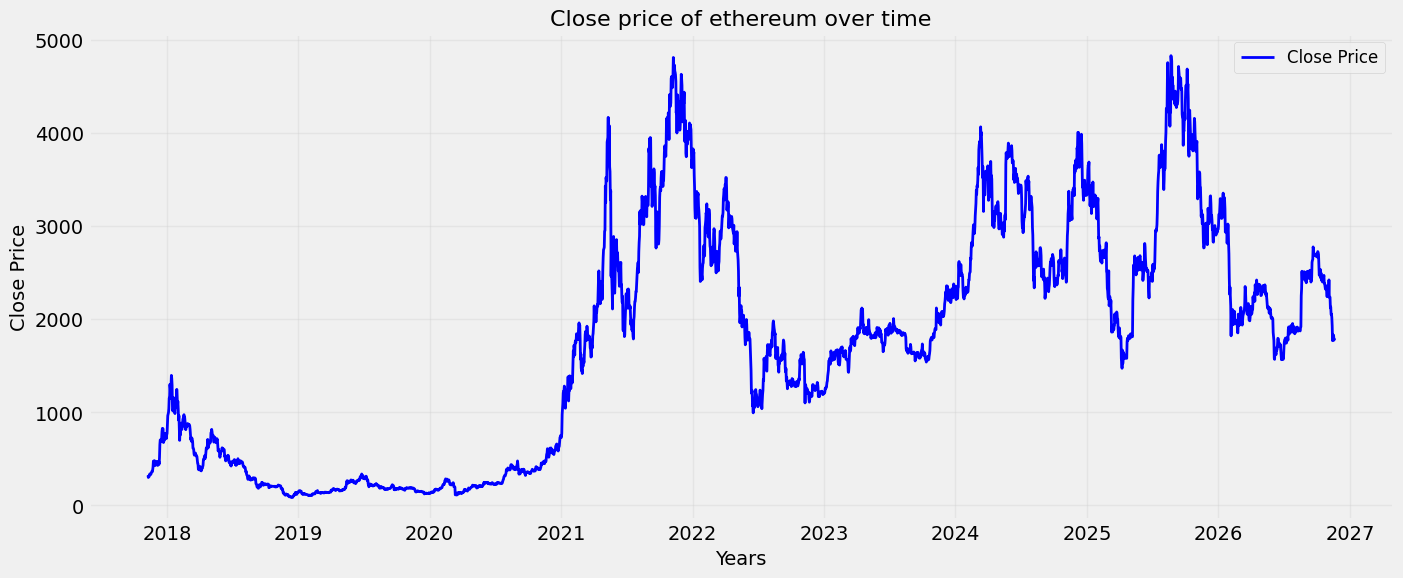

In [9]:
plt.figure(figsize = (15, 6))
plt.plot(closing_price.index, closing_price['Close'], label = 'Close Price', color = 'blue', linewidth =2)
plt.title("Close price of ethereum over time", fontsize = 16)
plt.xlabel("Years", fontsize = 14)
plt.ylabel('Close Price', fontsize = 14)
plt.grid(alpha = 0.3)
plt.legend(fontsize = 12)
plt.show()

In [10]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(closing_price[['Close']].dropna())

In [11]:
len(scaled_data)

3298

In [12]:
from keras.models import Sequential
from keras.layers import Dense, LSTM, Input

/Users/mohdamaanansari/Desktop/Projects/CryptoVision/ML Service/venv/lib/python3.13/site-packages/keras/src/export/tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):


In [13]:
x_data = []
y_data = []
base_days =100
for i in range(base_days, len(scaled_data)):
    x_data.append(scaled_data[i-base_days: i])
    y_data.append(scaled_data[i])
x_data = np.array(x_data)
y_data = np.array(y_data)

In [14]:
train_size = int(len(x_data) * 0.9)
x_train , y_train = x_data[:train_size], y_data[:train_size]
x_test, y_test = x_data[train_size:], y_data[train_size:]

In [15]:
model = Sequential([
    Input(shape=(x_train.shape[1], 1)),
    LSTM(128, return_sequences=True),
    LSTM(64),
    Dense(25),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 100, 128)       │        66,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 25)             │         1,625 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 117,619 (459.45 KB)

 Trainable params: 117,619 (459.45 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
model.fit(x_train, y_train, batch_size = 50, epochs = 5)

Epoch 1/5
58/58 ━━━━━━━━━━━━━━━━━━━━ 5s 62ms/step - loss: 0.0089
Epoch 2/5
58/58 ━━━━━━━━━━━━━━━━━━━━ 4s 62ms/step - loss: 0.0013
Epoch 3/5
58/58 ━━━━━━━━━━━━━━━━━━━━ 4s 64ms/step - loss: 0.0012
Epoch 4/5
58/58 ━━━━━━━━━━━━━━━━━━━━ 4s 64ms/step - loss: 0.0012
Epoch 5/5
58/58 ━━━━━━━━━━━━━━━━━━━━ 4s 63ms/step - loss: 0.0011


In [17]:
predictions = model.predict(x_test)
inv_predictions = scaler.inverse_transform(predictions)
inv_y_test = scaler.inverse_transform(y_test)

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step


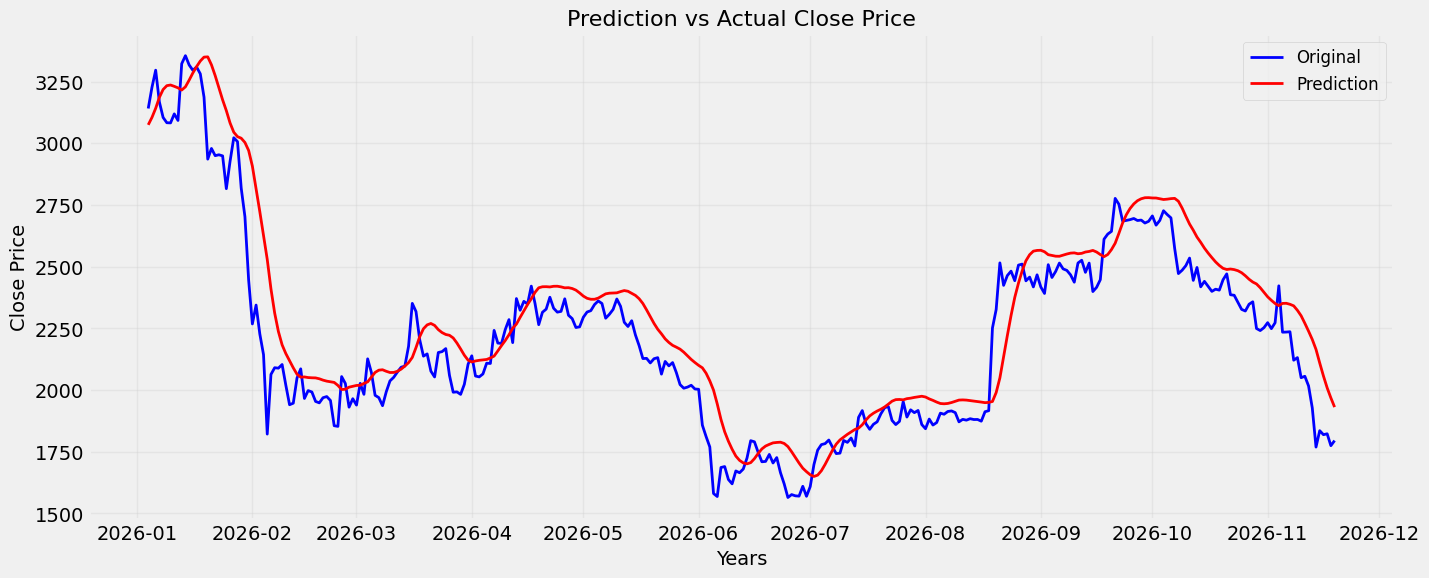

In [18]:
plotting_data = pd.DataFrame(
    {
        'Original': inv_y_test.flatten(), 
        'Prediction': inv_predictions.flatten(),
    }, index = closing_price.index[train_size + base_days:]
)

plt.figure(figsize = (15, 6))
plt.plot(plotting_data.index, plotting_data['Original'], label = 'Original', color = 'blue', linewidth =2)
plt.plot(plotting_data.index, plotting_data['Prediction'], label = 'Prediction', color = 'red',  linewidth =2)

plt.title("Prediction vs Actual Close Price", fontsize = 16)
plt.xlabel("Years", fontsize = 14)
plt.ylabel('Close Price', fontsize = 14)
plt.grid(alpha = 0.3)
plt.legend(fontsize = 12)
plt.show()

In [19]:
last_100  = scaled_data[-100:].reshape(1, -1, 1)
future_predictions=[]
for _ in range(10):
    next_days = model.predict(last_100)
    future_predictions.append(scaler.inverse_transform(next_days))
    last_100 = np.append(last_100[:, 1:, :], next_days.reshape(1, 1, -1), axis = 1)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 166ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step


In [20]:
future_predictions

[array([[1901.246]], dtype=float32),
 array([[1888.5723]], dtype=float32),
 array([[1885.972]], dtype=float32),
 array([[1889.5945]], dtype=float32),
 array([[1897.0928]], dtype=float32),
 array([[1907.0464]], dtype=float32),
 array([[1918.5973]], dtype=float32),
 array([[1931.2279]], dtype=float32),
 array([[1944.6211]], dtype=float32),
 array([[1958.5824]], dtype=float32)]

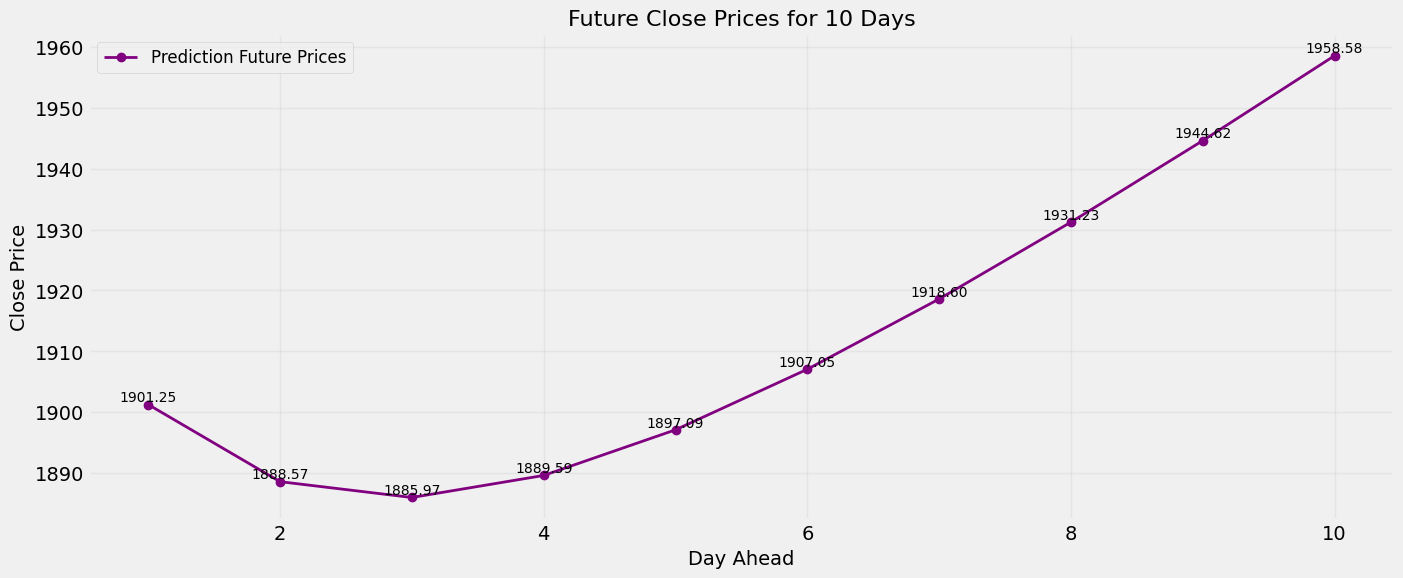

In [21]:
future_predictions = np.array(future_predictions).flatten()

plt.figure(figsize = (15, 6))
plt.plot(range(1, 11), future_predictions, marker="o" ,label = 'Prediction Future Prices', color = 'purple', linewidth =2)

for i, val in enumerate(future_predictions):
    plt.text(i+1,val,  f'{val:.2f}', fontsize = 10, ha = 'center', va = 'bottom', color='black')

plt.title("Future Close Prices for 10 Days", fontsize = 16)
plt.xlabel("Day Ahead", fontsize = 14)
plt.ylabel('Close Price', fontsize = 14)
plt.grid(alpha = 0.3)
plt.legend(fontsize = 12)
plt.show()

In [23]:
model.save("model_eth.keras")